In [2]:
# ==========================================
# LOAD DATASET DAN MODEL DEIT-TINY
# ==========================================

import sys
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. PROJECT DIRECTORY
# ==========================================

PROJECT_DIR = Path(r"D:\Tugas_CNN_IPSD")

sys.path.insert(0, str(PROJECT_DIR))

# ==========================================
# 2. IMPORT DATASET DAN MODEL
# ==========================================

from preprocesing_data.data_loader import create_data_loaders

from model.deit_tiny.model_deit_tiny import (
    create_model,
    DEVICE
)

# ==========================================
# 3. LOAD DATASET
# ==========================================

train_loader, val_loader, test_loader, class_names, num_classes = (
    create_data_loaders()
)

print("========================================")
print("INFORMASI DATASET TESTING")
print("========================================")
print("Jumlah kelas  :", num_classes)
print("Data training :", len(train_loader.dataset))
print("Data validasi :", len(val_loader.dataset))
print("Data testing  :", len(test_loader.dataset))

# ==========================================
# 4. LOAD MODEL DEIT-TINY
# ==========================================

model = create_model(num_classes)

CHECKPOINT_PATH = Path(
    r"D:\Matkul semester 3\Tugas_CNN_IPSD\results\checkpoints\best_deit_tiny.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Ambil state dictionary
if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]

elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]

elif "model" in checkpoint:
    state_dict = checkpoint["model"]

else:
    state_dict = checkpoint

# Hilangkan prefix module jika ada
state_dict = {
    key.replace("module.", "", 1): value
    for key, value in state_dict.items()
}

model.load_state_dict(state_dict)
model.eval()

print("\n========================================")
print("MODEL BERHASIL DIMUAT")
print("========================================")
print("Model          : DeiT-Tiny")
print("Arsitektur     : deit_tiny_patch16_224")
print("Jumlah kelas   :", num_classes)
print("Checkpoint     :", CHECKPOINT_PATH.name)
print("Device         :", DEVICE)
print("========================================")

d:\Tugas_CNN_IPSD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



INFORMASI DATASET IKAN
Total gambar ditemukan : 4411
Total kelas ikan       : 483
Gambar tidak ditemukan: 0
Baris indeks tidak valid: 0

PEMBAGIAN DATASET
Training   : 2821 gambar
Validation : 594 gambar
Testing    : 996 gambar
-----------------------------------
Persentase Training   : 63.95%
Persentase Validation : 13.47%
Persentase Testing    : 22.58%
-----------------------------------
Total kelas           : 483
Kelas training        : 483
Kelas validation      : 483
Kelas testing         : 483

DATA LOADER BERHASIL DIBUAT
Jumlah kelas : 483
Batch size   : 16
Image size   : 224
Device       : cpu
INFORMASI DATASET TESTING
Jumlah kelas  : 483
Data training : 2821
Data validasi : 594
Data testing  : 996



MODEL BERHASIL DIMUAT
Model          : DeiT-Tiny
Arsitektur     : deit_tiny_patch16_224
Jumlah kelas   : 483
Checkpoint     : best_deit_tiny.pth
Device         : cpu


HASIL TESTING DEIT-TINY
Accuracy  : 0.5633
Precision : 0.5392
Recall    : 0.5633
F1-Score  : 0.5176

CLASSIFICATION REPORT
                                 precision    recall  f1-score   support

                       A73EGS-P       1.00      0.50      0.67         2
                       CUNWCB-Y       1.00      0.50      0.67         2
        Istiophorus_platypterus       0.33      1.00      0.50         1
                       P1ROZC-Z       1.00      0.50      0.67         4
                       PQV7DP-S       0.00      0.00      0.00         2
         acanthaluteres_brownii       0.00      0.00      0.00         1
  acanthaluteres_spilomelanurus       0.00      0.00      0.00         1
        acanthaluteres_vittiger       0.33      0.50      0.40         2
           acanthistius_cinctus       0.67      1.00      0.80         2
        acanthopagrus_australis       0.00      0.00      0.00         1
            acanthopagrus_berda       1.00      0.33      0.50         3


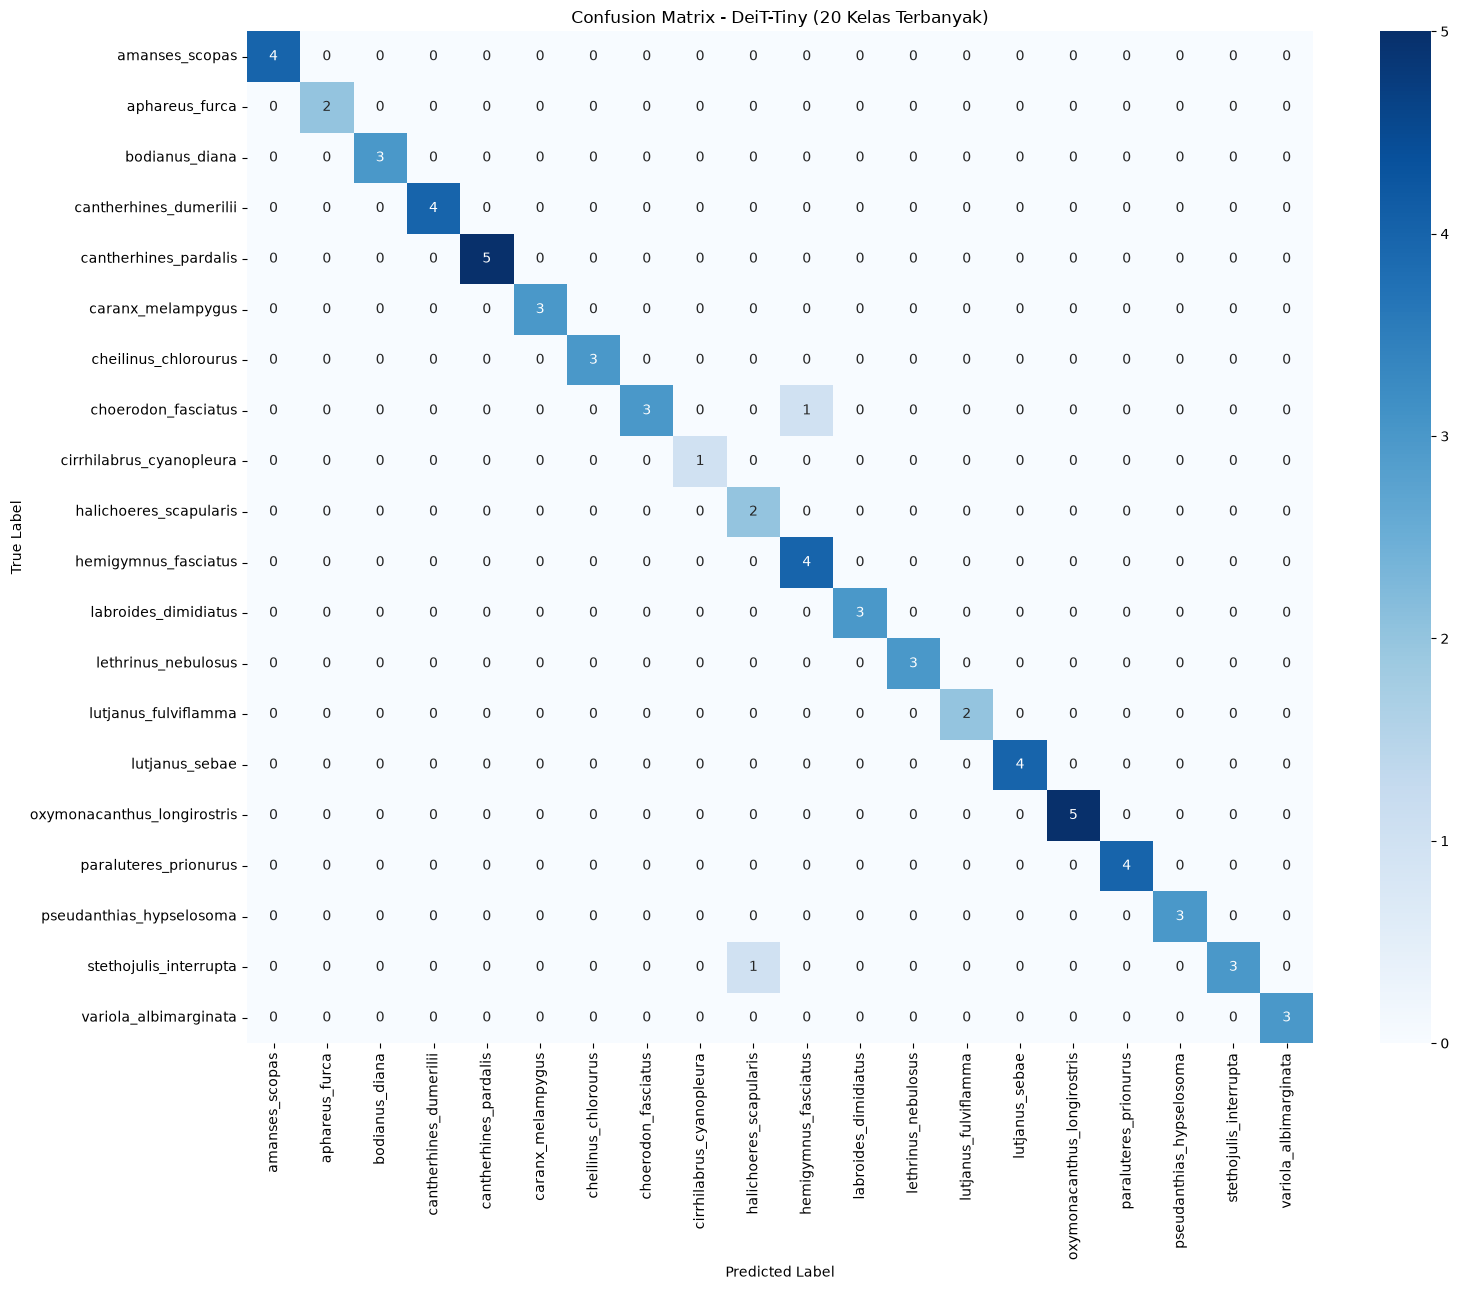

In [4]:
# ==========================================
# TESTING DAN EVALUASI DEIT-TINY
# ==========================================
import seaborn as sns
all_labels = []
all_predictions = []

model.eval()

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

print("HASIL TESTING DEIT-TINY")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0
))
# ==========================================
# CONFUSION MATRIX - 20 KELAS TERBANYAK
# ==========================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Ambil 20 kelas dengan data testing terbanyak
top_classes = (
    pd.Series(all_labels)
    .value_counts()
    .head(20)
    .index
    .sort_values()
    .tolist()
)

# Filter data aktual dan prediksi untuk 20 kelas tersebut
filtered_indices = [
    i for i, label in enumerate(all_labels)
    if label in top_classes
]

y_true = [all_labels[i] for i in filtered_indices]
y_pred = [all_predictions[i] for i in filtered_indices]

# Buat confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=top_classes
)

labels = [class_names[i] for i in top_classes]

plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - DeiT-Tiny (20 Kelas Terbanyak)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

np.savez(
    "deit_tiny_test_results.npz",
    all_labels=np.array(all_labels),
    all_predictions=np.array(all_predictions),
    class_names=np.array(class_names)
)
print("Hasil testing berhasil disimpan.")

Hasil testing berhasil disimpan.
